In [1]:
import os
import utils
import torch
import pickle
import numpy as np
import matplotlib.pyplot as plt

from torch import nn
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import roc_curve, roc_auc_score

C:\Users\Francesco De Luca\miniconda3\envs\DL_2026_2027\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# PARAMETRI

In [2]:
EPOCHS = 10
BATCH_SIZE = 32
LEARNING_RATE = 0.001
DEVICE = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.device('cpu')

print(f"DEVICE: {DEVICE}")

DEVICE: cuda


TRAIN SET: 6013 immagini (5923 inlier, 90 anomalie)


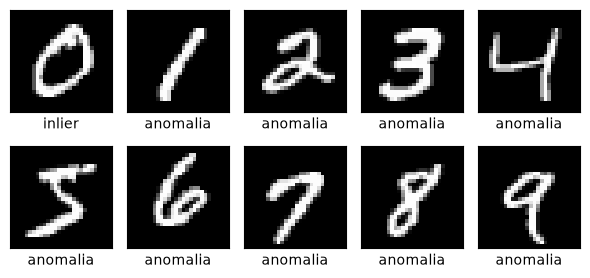

In [3]:
from datasets.datasets import load_MNIST
mnist_train, _, _, _ = load_MNIST(batch_size=BATCH_SIZE, verbose=False)

# DATASET CONTAMINATO: tutte le immagini di training della cifra INLIER_DIGIT + SIZE immagini di ciascuna altra cifra (anomalie)
INLIER_DIGIT = 0
SIZE = 10

targets = mnist_train.targets
inlier_idx = (targets == INLIER_DIGIT).nonzero().squeeze(1)
outlier_idx = torch.cat([(targets == c).nonzero().squeeze(1)[:SIZE] for c in range(10) if c != INLIER_DIGIT])
idx = torch.cat([inlier_idx, outlier_idx])   # prima gli inlier, in fondo le anomalie

# Non c'è un test set: l'autoencoder si addestra sui dati contaminati e l'outlierness si calcola sugli stessi dati
train_dataset = Subset(mnist_train, idx.tolist())
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False)   # stessi dati, in ordine, per la valutazione

print(f"TRAIN SET: {len(train_dataset)} immagini ({len(inlier_idx)} inlier, {len(outlier_idx)} anomalie)")

examples = [idx[targets[idx] == c][0].item() for c in range(10)]   # primo esempio di ogni cifra (indici in mnist_train)
plt.figure(figsize=(6, 3))
for c, i in enumerate(examples):
    img, label = mnist_train[i]
    plt.subplot(2, 5, c + 1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(img.squeeze(), cmap="gray")
    plt.xlabel('inlier' if label == INLIER_DIGIT else 'anomalia')
plt.tight_layout()
plt.show()

# MODELLO

In [4]:
#Parametri del modello
INPUT_SIZE = 784
H1 = 128
H2 = 64

In [5]:
encoder = nn.Sequential(
    nn.Flatten(),                           # (B, 1, 28, 28) -> (B, 784)
    nn.Linear(INPUT_SIZE, H1), nn.ReLU(),
    nn.Linear(H1, H2), nn.ReLU(),
)

decoder = nn.Sequential(
    nn.Linear(H2, H1), nn.ReLU(),
    nn.Linear(H1, INPUT_SIZE), nn.Sigmoid(),
    nn.Unflatten(1, (1, 28, 28)),           # (B, 784) -> (B, 1, 28, 28)
)

autoencoder = nn.Sequential(encoder, decoder).to(DEVICE)

# Versione equivalente come classe:
# class AutoEncoder(nn.Module):
#     def __init__(self, input_size, hidden_size_1, hidden_size_2):
#         super().__init__()
#         self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(input_size, hidden_size_1), nn.ReLU(),
#                                      nn.Linear(hidden_size_1, hidden_size_2), nn.ReLU())
#         self.decoder = nn.Sequential(nn.Linear(hidden_size_2, hidden_size_1), nn.ReLU(),
#                                      nn.Linear(hidden_size_1, input_size), nn.Sigmoid(),
#                                      nn.Unflatten(1, (1, 28, 28)))
#     def forward(self, x):
#         return self.decoder(self.encoder(x))
# autoencoder = AutoEncoder(INPUT_SIZE, H1, H2).to(DEVICE)
# encoder = autoencoder.encoder

optimizer = torch.optim.Adam(autoencoder.parameters(), lr=LEARNING_RATE, eps=1e-7)
criterion = nn.MSELoss()

autoencoder

Sequential(
  (0): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
  )
  (1): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=784, bias=True)
    (3): Sigmoid()
    (4): Unflatten(dim=1, unflattened_size=(1, 28, 28))
  )
)

# ADDESTRAMENTO

100%|██████████| 10/10 [00:19<00:00,  1.92s/it]


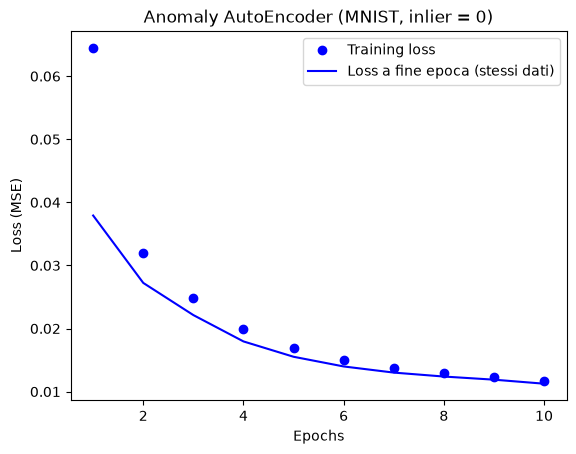

In [6]:
os.makedirs('histories', exist_ok=True)

filename = "anomaly3"
hist_path = f'histories/{filename}.hist'
weights_path = f'histories/{filename}.pt'

if os.path.isfile(hist_path) and os.path.isfile(weights_path):
    with open(hist_path, 'rb') as hist_file:
        history_dict = pickle.load(hist_file)
    autoencoder.load_state_dict(torch.load(weights_path, map_location=DEVICE))
else:
    history_dict = utils.train_autoencoder(autoencoder, optimizer, criterion,
                                     train_loader, test_loader, EPOCHS, DEVICE)
    with open(hist_path, 'wb') as hist_file:
        pickle.dump(history_dict, hist_file)
    torch.save(autoencoder.state_dict(), weights_path)

epochs = range(1, len(history_dict['loss']) + 1)
plt.figure()
plt.plot(epochs, history_dict['loss'], 'bo', label='Training loss')
plt.plot(epochs, history_dict['val_loss'], 'b', label='Loss a fine epoca (stessi dati)')
plt.title(f'Anomaly AutoEncoder (MNIST, inlier = {INLIER_DIGIT})')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.legend(loc='upper right')
plt.show()

# VALUTAZIONE

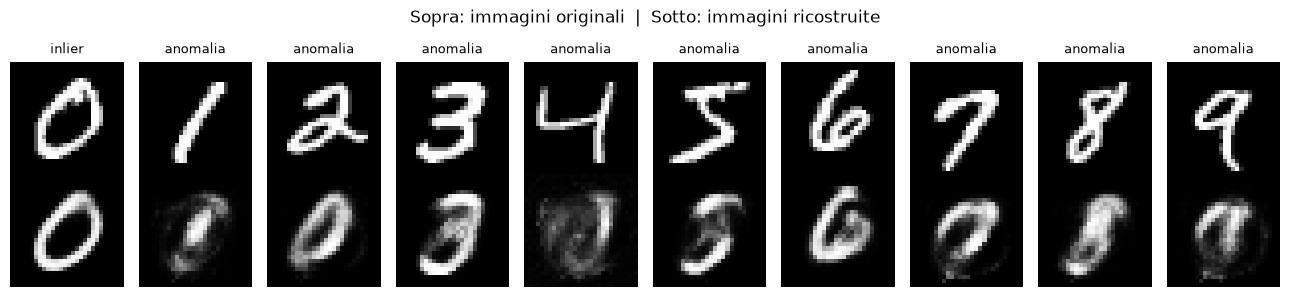

In [7]:
# TEST: ricostruzione del primo esempio di ogni cifra (inlier e anomalie)
autoencoder.eval()
x = torch.stack([mnist_train[i][0] for i in examples])
with torch.no_grad():
    x_rec = autoencoder(x.to(DEVICE)).cpu()

n_show = len(examples)
plt.figure(figsize=(1.3 * n_show, 3))
for c in range(n_show):
    plt.subplot(2, n_show, c + 1)
    plt.imshow(x[c].squeeze(), cmap='gray')
    plt.title('inlier' if c == INLIER_DIGIT else 'anomalia', fontsize=9)
    plt.axis('off')
    plt.subplot(2, n_show, n_show + c + 1)
    plt.imshow(x_rec[c].squeeze(), cmap='gray')
    plt.axis('off')
plt.suptitle('Sopra: immagini originali  |  Sotto: immagini ricostruite')
plt.tight_layout()
plt.show()

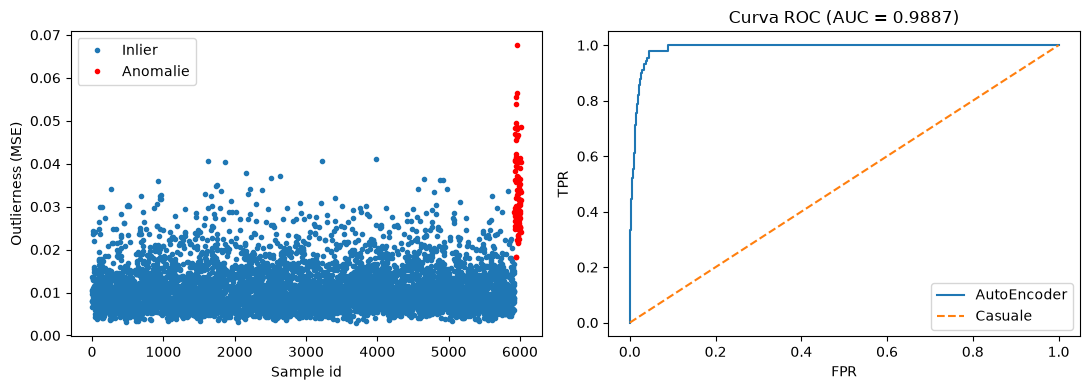

In [8]:
# ANOMALY DETECTION: l'outlierness di un'immagine è il suo errore di ricostruzione (MSE)
autoencoder.eval()
scores, labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        x_rec = autoencoder(x.to(DEVICE)).cpu()
        scores.append(((x_rec - x) ** 2).flatten(1).mean(dim=1))   # MSE di ogni singola immagine
        labels.append((y != INLIER_DIGIT).long())                   # 1 = anomalia, 0 = inlier
outlierness = torch.cat(scores).numpy()
labels = torch.cat(labels).numpy()

fpr, tpr, thresholds = roc_curve(labels, outlierness)
auc = roc_auc_score(labels, outlierness)

ids = np.arange(len(outlierness))
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(ids[labels == 0], outlierness[labels == 0], '.', label='Inlier')
plt.plot(ids[labels == 1], outlierness[labels == 1], '.', color='red', label='Anomalie')
plt.xlabel('Sample id')
plt.ylabel('Outlierness (MSE)')
plt.legend(loc='upper left')
plt.subplot(1, 2, 2)
plt.plot(fpr, tpr, label='AutoEncoder')
plt.plot([0, 1], [0, 1], linestyle='--', label='Casuale')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title(f'Curva ROC (AUC = {auc:.4f})')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

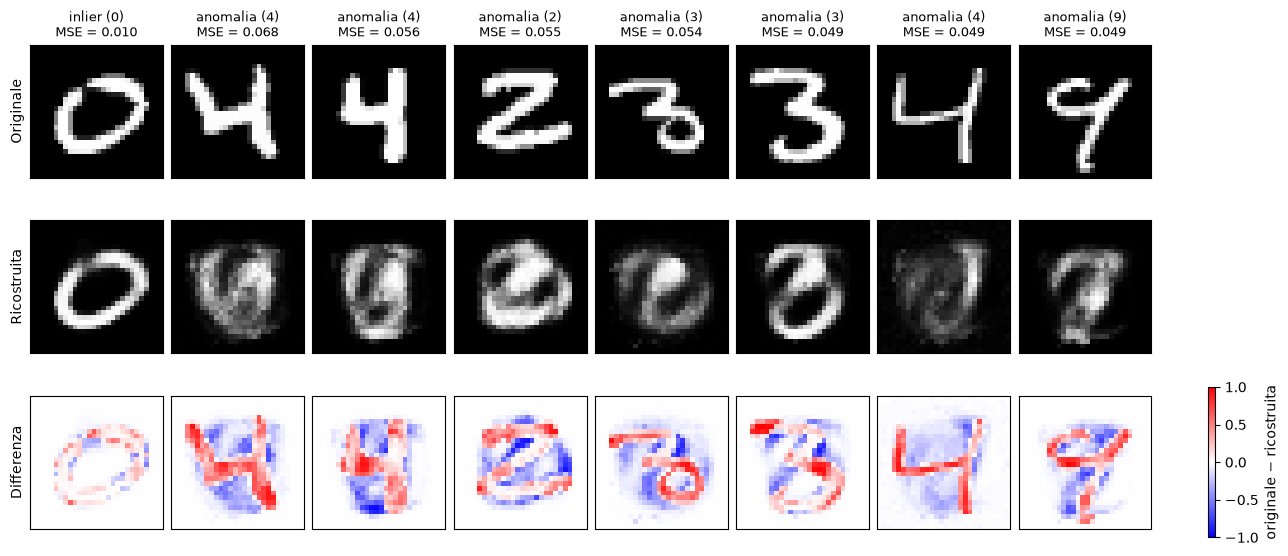

In [13]:
# SPIEGAZIONE DELL'ANOMALIA: differenza tra immagine originale e ricostruita (usa outlierness e labels della cella precedente)
#   rosso = tratti presenti nell'originale che l'autoencoder non riesce a ricostruire
#   blu   = tratti che l'autoencoder "aggiunge" perché si aspetta di vedere un inlier
# L'outlierness (MSE) è la media dei quadrati di questa mappa
order = np.argsort(outlierness)
show = [order[len(order) // 2]] + list(order[::-1][:7])   # un inlier tipico (outlierness mediana) + le 7 immagini più anomale

autoencoder.eval()
x = torch.stack([train_dataset[j][0] for j in show])
digits = [train_dataset[j][1] for j in show]
with torch.no_grad():
    x_rec = autoencoder(x.to(DEVICE)).cpu()
diff = (x - x_rec).squeeze(1)   # (N, 28, 28), valori in [-1, 1]

n_show = len(show)
fig, axes = plt.subplots(3, n_show, figsize=(1.6 * n_show, 5.5), layout='constrained')
for c, j in enumerate(show):
    tipo = 'anomalia' if labels[j] == 1 else 'inlier'
    axes[0, c].imshow(x[c].squeeze(), cmap='gray')
    axes[0, c].set_title(f'{tipo} ({digits[c]})\nMSE = {outlierness[j]:.3f}', fontsize=9)
    axes[1, c].imshow(x_rec[c].squeeze(), cmap='gray')
    im = axes[2, c].imshow(diff[c], cmap='bwr', vmin=-1, vmax=1)
    for ax in axes[:, c]:
        ax.set_xticks([])
        ax.set_yticks([])
for r, name in enumerate(['Originale', 'Ricostruita', 'Differenza']):
    axes[r, 0].set_ylabel(name)
fig.colorbar(im, ax=axes[2, :], shrink=0.9, label='originale − ricostruita')
plt.show()